# Tarea 1 · Parte 1 — Recolección, limpieza y EDA

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

| Campo | Valor |
| :--- | :--- |
| Fecha de descarga | **2026-10-18** |
| Opción elegida | **C – Comparada** (200 La República + 200 El Comercio = 400) |
| Categorías | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |
| URL base La República | `https://larepublica.pe/rss/<seccion>.xml` (RSS oficial por sección) |
| URL base El Comercio | `https://elcomercio.pe/sitemap/news/<seccion>/?outputType=xml` (sitemap de noticias) |
| Histórico La República | `https://web.archive.org/web/<timestamp>id_/https://larepublica.pe/rss/<seccion>.xml` |

### Revisión de `robots.txt` y decisiones de recolección

- **La República** (`larepublica.pe/robots.txt`): permite explícitamente `Allow: /rss/*` y `Allow: /sitemap/*`; prohíbe el buscador (`/buscador*`), la paginación de secciones (`/*/pag/*`, `/*/*/page/*`), `/archivo/*` y `/tag/*`. Sus RSS por sección solo exponen las **últimas 10–20 noticias**, por lo que no alcanza para 200 en una sola descarga. Como no se puede paginar ni buscar, se recuperaron **copias históricas de esos mismos RSS en la Wayback Machine** (archive.org, índice CDX), máximo 12 copias por sección.
- **El Comercio** (`elcomercio.pe/robots.txt`): solo prohíbe `/catalogo/`, `/buscar/` y archivos antiguos; publica sitemaps por sección. Su RSS por categoría devolvió muy pocos ítems (0–10), así que se usó el **sitemap de noticias** (`news:title`, `news:publication_date`, ~100 URLs por sección). La bajada se obtiene de la `meta description` de cada nota al validar su URL.
- Buenas prácticas: `User-Agent` descriptivo, pausa aleatoria de **1–2 s** entre solicitudes, reintentos limitados, y respaldo crudo de cada XML en `datos/raw/`.
- El código de descarga está en `scraping.py` (importado aquí) para que el notebook sea legible.

In [1]:
import sys, json
from datetime import date
import pandas as pd
import plotly.express as px
import plotly.io as pio
import scraping as sc

# Interactivo en VS Code/Jupyter + imagen PNG estática para que se vea en GitHub
pio.renderers.default = "plotly_mimetype+png"
pd.set_option("display.max_colwidth", 120)
SEED = 42
POR_CELDA = 50          # 50 noticias x 4 categorías x 2 medios = 400
DESCARGAR = False       # True = volver a descargar; False = usar respaldos de datos/raw/
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| hoy", date.today())

Python 3.12.2 | pandas 3.0.6 | hoy 2026-10-18


## 1. Extracción

In [2]:
if DESCARGAR:
    sc.el_comercio()
    sc.la_republica_actual()
    sc.la_republica_wayback(max_snapshots=12)

crudo = pd.DataFrame(sc.cargar_raw())
print("Archivos crudos en datos/raw:", len(list(sc.RAW.glob('*.xml'))))
print("Filas crudas (con repeticiones entre copias del RSS):", len(crudo))
crudo.groupby(["medio", "fuente"]).size().rename("filas").to_frame()

Archivos crudos en datos/raw: 55
Filas crudas (con repeticiones entre copias del RSS): 3315


filas
medio        fuente        
El Comercio  sitemap    400
La Republica rss         53
             wayback   2862

## 2. Limpieza y normalización

In [3]:
descartes = []
df = crudo.copy()
for c in ["titular", "bajada", "url"]:
    df[c] = df[c].fillna("").str.strip()

# Fecha normalizada a AAAA-MM-DD (hora de Lima)
df["fecha_dt"] = pd.to_datetime(df["fecha"], utc=True, format="mixed").dt.tz_convert("America/Lima")
df["fecha"] = df["fecha_dt"].dt.strftime("%Y-%m-%d")

n = len(df)
df = df[df["titular"] != ""]
descartes.append(("Titular vacío", n - len(df)))

n = len(df)
df = df.sort_values("fecha_dt", ascending=False).drop_duplicates("url")
descartes.append(("URL duplicada (misma nota en varias copias del RSS/sitemap)", n - len(df)))

n = len(df)
df = df.drop_duplicates(["medio", "titular"])
descartes.append(("Titular duplicado en el mismo medio (URL distinta)", n - len(df)))

# seccion_original = ruta de sección tal como aparece en la URL del diario
df["feed"] = df["seccion_original"]
df["seccion_original"] = df["url"].map(sc.seccion_desde_url)
print("Filas únicas tras limpieza básica:", len(df))

Filas únicas tras limpieza básica: 3224


### Tabla de equivalencias sección → categoría

Se mapea el **primer nivel** de la ruta de sección de la URL. Las secciones que no corresponden a ninguna de las 4 categorías (opinión, mundo, cultura, data, etc.) **se descartan**; no se crea una quinta categoría.

In [4]:
MAPEO = {
    "politica": "politica", "elecciones": "politica",
    "economia": "economia",
    "deportes": "deportes", "deporte-total": "deportes",
    "futbol-peruano": "deportes", "futbol-espanol": "deportes",
    "ciencia": "ciencia_tecnologia", "tecnologia": "ciencia_tecnologia",
}
df["seccion_n1"] = df["seccion_original"].str.split("/").str[0]
df["etiqueta"] = df["seccion_n1"].map(MAPEO)

tabla_mapeo = (df.groupby(["medio", "seccion_n1"], dropna=False)
                 .agg(n=("url", "size"), ejemplos_seccion_original=("seccion_original", lambda s: ", ".join(s.value_counts().index[:3])))
                 .reset_index())
tabla_mapeo["categoria_final"] = tabla_mapeo["seccion_n1"].map(MAPEO).fillna("— descartada —")
tabla_mapeo.sort_values(["medio", "categoria_final", "n"], ascending=[True, True, False])

,medio,seccion_n1,n,ejemplos_seccion_original,categoria_final
9,El Comercio,tecnologia,95,"tecnologia/actualidad, tecnologia/inteligencia-artificial, tecnologia/ciencias",ciencia_tecnologia
1,El Comercio,deporte-total,98,"deporte-total/futbol-peruano, deporte-total/futbol-mundial, deporte-total",deportes
3,El Comercio,economia,99,"economia/peru, economia/mercados, economia",economia
7,El Comercio,politica,91,"politica, politica/congreso, politica/gobierno",politica
5,El Comercio,elecciones,1,elecciones,politica
6,El Comercio,opinion,6,opinion/columnistas,— descartada —
2,El Comercio,ecdata,4,ecdata,— descartada —
0,El Comercio,bbc-news-mundo,2,bbc-news-mundo,— descartada —
8,El Comercio,ruedas-tuercas,2,ruedas-tuercas/automotriz,— descartada —
4,El Comercio,eldominical,1,eldominical/ciencia,— descartada —


In [5]:
fuera = df[df["etiqueta"].isna()]
descartes.append(("Sección fuera de las 4 categorías", len(fuera)))
print("Secciones descartadas:", fuera["seccion_n1"].value_counts().to_dict())
df = df[df["etiqueta"].notna()]
df.groupby(["medio", "etiqueta"]).size().unstack()

Secciones descartadas: {'mundo': 39, 'opinion': 12, 'ecdata': 4, 'ruedas-tuercas': 2, 'bbc-news-mundo': 2, 'cultural': 2, 'estados-unidos': 2, 'eldominical': 1, 'cine-series': 1, 'tendencias': 1, 'mexico': 1, 'sociedad': 1, 'domingo': 1}


etiqueta,ciencia_tecnologia,deportes,economia,politica
medio,,,,
El Comercio,95,98,99,92
La Republica,566,921,514,770


### Muestra balanceada y validación de URLs

Opción C: **200 noticias por medio**. Para que el clasificador no herede el desbalance del universo disponible (p. ej. deportes domina La República), se fija una cuota de **50 por categoría y por medio** (100 por categoría, en línea con las ~90–100 que pide el enunciado).
Dentro de cada grupo la selección es **aleatoria** (`random_state=42`). Cada URL se valida con una petición real (HTTP 200); si falla, se reemplaza por la siguiente del orden aleatorio. En la misma petición se toma la `meta description` como bajada cuando el feed no la trae (El Comercio); si tampoco hay description, la nota se reemplaza. Resultados cacheados en `datos/raw/paginas_validadas.json`.

In [6]:
cache = sc.cargar_cache()
elegidas, no_funcionales, sin_bajada = [], 0, 0
for (medio, etq), g in df.sample(frac=1, random_state=SEED).groupby(["medio", "etiqueta"]):
    k = 0
    for _, fila in g.iterrows():
        if k == POR_CELDA:
            break
        v = sc.validar_url(fila["url"], cache)
        if not v["ok"]:
            no_funcionales += 1
            continue
        fila = fila.copy()
        if not fila["bajada"]:
            fila["bajada"] = v["bajada"]
        if not fila["bajada"]:
            sin_bajada += 1
            continue
        elegidas.append(fila)
        k += 1
    print(f"{medio:13s} {etq:20s} {k} válidas")

final = pd.DataFrame(elegidas)
descartes.append(("URL no funcional al validar", no_funcionales))
descartes.append(("Sin bajada disponible", sin_bajada))
descartes.append(("Excedente no seleccionado al azar (cuota 50 por categoría y medio)", len(df) - len(final) - no_funcionales - sin_bajada))

El Comercio   ciencia_tecnologia   50 válidas


El Comercio   deportes             50 válidas


El Comercio   economia             50 válidas


El Comercio   politica             50 válidas


La Republica  ciencia_tecnologia   50 válidas


La Republica  deportes             50 válidas


La Republica  economia             50 válidas


La Republica  politica             50 válidas


In [7]:
reporte = pd.DataFrame(descartes, columns=["motivo", "noticias_descartadas"])
print("Filas crudas:", len(crudo), "| filas finales:", len(final))
reporte

Filas crudas: 3315 | filas finales: 400


,motivo,noticias_descartadas
0,Titular vacío,0
1,URL duplicada (misma nota en varias copias del RSS/sitemap),90
2,Titular duplicado en el mismo medio (URL distinta),1
3,Sección fuera de las 4 categorías,69
4,URL no funcional al validar,1
5,Sin bajada disponible,0
6,Excedente no seleccionado al azar (cuota 50 por categoría y medio),2754


## 3. Análisis exploratorio (Plotly Express)

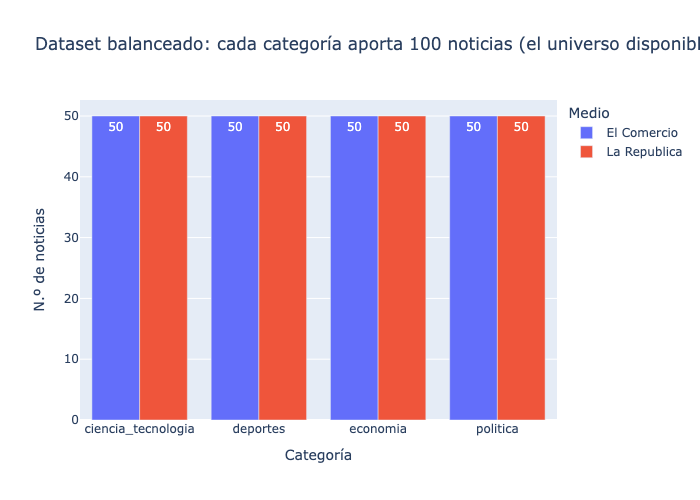

In [8]:
final["largo_titular"] = final["titular"].str.len()
dist = final.groupby(["etiqueta", "medio"]).size().reset_index(name="noticias")
pool = df.groupby(["medio", "etiqueta"]).size()
mayor = pool.idxmax()
fig1 = px.bar(dist, x="etiqueta", y="noticias", color="medio", barmode="group", text="noticias",
              title=(f"Dataset balanceado: cada categoría aporta {dist.groupby('etiqueta').noticias.sum().iloc[0]} noticias "
                     f"(el universo disponible estaba sesgado: {mayor[0]}/{mayor[1]} tenía {pool.max()} notas)"),
              labels={"etiqueta": "Categoría", "noticias": "N.º de noticias", "medio": "Medio"})
fig1.show()

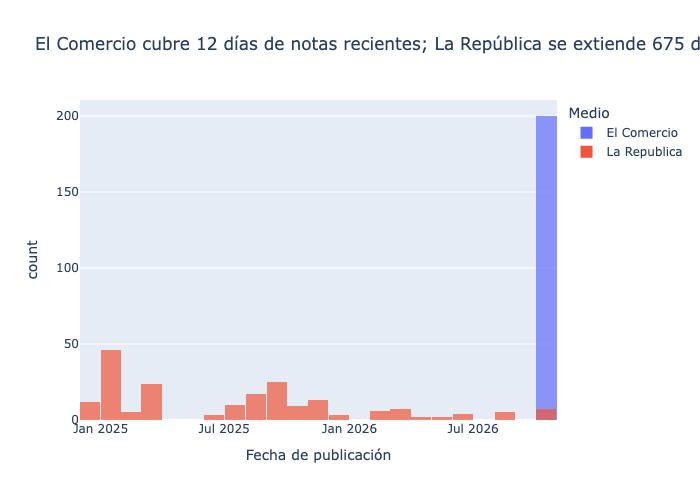

,min,max,dias
medio,,,
El Comercio,2026-10-06 08:05:08-05:00,2026-10-18 08:08:47-05:00,12
La Republica,2024-12-11 14:40:06-05:00,2026-10-18 04:30:00-05:00,675


In [9]:
rango = final.groupby("medio")["fecha_dt"].agg(["min", "max"])
dias = (rango["max"] - rango["min"]).dt.days
fig2 = px.histogram(final, x="fecha_dt", color="medio", nbins=40, barmode="overlay", opacity=0.7,
                    title=(f"El Comercio cubre {dias['El Comercio']} días de notas recientes; La República se extiende "
                           f"{dias['La Republica']} días por la muestra aleatoria sobre copias históricas del RSS"),
                    labels={"fecha_dt": "Fecha de publicación", "count": "N.º de noticias", "medio": "Medio"})
fig2.show()
rango.assign(dias=dias)

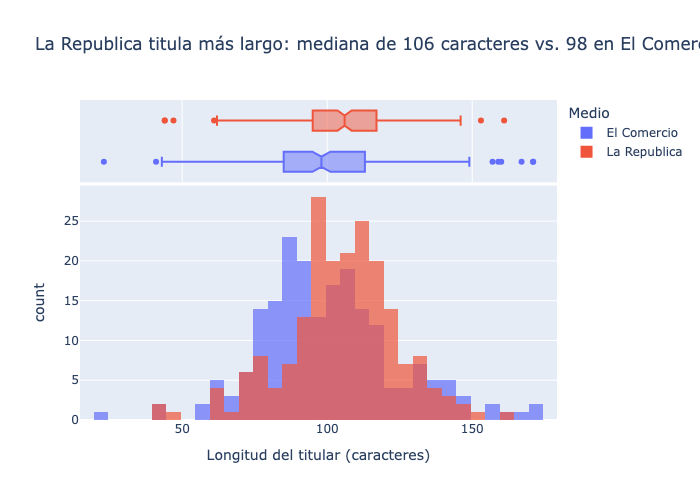

etiqueta,ciencia_tecnologia,deportes,economia,politica
medio,,,,
El Comercio,90.0,94.0,92.0,112.0
La Republica,104.0,108.0,108.0,100.0


In [10]:
med = final.groupby("medio")["largo_titular"].median()
largo, corto = med.idxmax(), med.idxmin()
fig3 = px.histogram(final, x="largo_titular", color="medio", nbins=30, barmode="overlay", opacity=0.7,
                    marginal="box",
                    title=(f"{largo} titula más largo: mediana de {med[largo]:.0f} caracteres vs. "
                           f"{med[corto]:.0f} en {corto}"),
                    labels={"largo_titular": "Longitud del titular (caracteres)", "medio": "Medio"})
fig3.show()
final.groupby(["medio", "etiqueta"])["largo_titular"].median().unstack().round(0)

## 4. Validación: titulares más largos y más cortos

In [11]:
cols = ["titular", "medio", "etiqueta", "largo_titular"]
print("5 titulares más largos")
display(final.nlargest(5, "largo_titular")[cols])
print("5 titulares más cortos")
display(final.nsmallest(5, "largo_titular")[cols])
print(f"Rango: {final.largo_titular.min()}–{final.largo_titular.max()} caracteres; coincide con los extremos del histograma.")

5 titulares más largos


,titular,medio,etiqueta,largo_titular
0,El furioso “Que se dedique a administrar” de Guede a Franco Velazco y un Quevedo que reconquistó a Comando Sur: Lo q...,El Comercio,deportes,171
83,"“Con Mano Menezes el mejor jugador de la selección ha sido un ecuatoriano”: Bruno Cavassa, Coki Gonzales, Jorge Este...",El Comercio,deportes,171
54,“Creo que puedo llegar a un top 3 sin que nadie se quede botado”: Raúl ‘Mono’ Orlandini le responde a El Comercio so...,El Comercio,deportes,167
2142,"Interbank comenzó a aplicar cargos por transferencias a clientes en Perú que no cumplan con este requisito, pero ofr...",La Republica,economia,161
257,"Juan Sheput sobre eventual suspensión del viaje del papa León XIV al Perú: “Es posible, pero todavía no está la pala...",El Comercio,politica,160


5 titulares más cortos


,titular,medio,etiqueta,largo_titular
105,AlaCena no tiene precio,El Comercio,economia,23
176,La evolución de la confianza en los pagos,El Comercio,economia,41
106,Premio Nobel de Economía: la macro es micro,El Comercio,economia,43
1172,Resumen: Fiorentina y Torino igualaron 1 a 1,La Republica,deportes,44
1134,Inter amplía su ventaja y vence 3-1 a Empoli,La Republica,deportes,44


Rango: 23–171 caracteres; coincide con los extremos del histograma.


## 5. Exportación de `datos/noticias.csv`

In [12]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
salida = final[COLUMNAS].sample(frac=1, random_state=SEED).reset_index(drop=True)
assert salida["url"].is_unique and salida["etiqueta"].isin(set(MAPEO.values())).all()
salida.to_csv("datos/noticias.csv", index=False)
print(salida.shape)
salida.head()

(400, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Científicos descubren el origen de la papa moderna: un cruce con el tomate hace 9 millones de años,"Un estudio revela que la papa moderna surgió de un cruce entre tomates y especies chilenas hace 9 millones de años, ...",La Republica,ciencia,https://larepublica.pe/ciencia/2025/08/05/cientificos-descubren-el-origen-de-la-papa-moderna-un-cruce-con-el-tomate-...,2025-08-09,ciencia_tecnologia
1,Christian Cueva recibe nuevo apodo en Ecuador tras cautivar a Emelec con brillante asistencia,"El '10' del Bombillo, quien fue clave en el triunfo más reciente de su equipo, recibió múltiples halagos por su buen...",La Republica,deportes,https://larepublica.pe/deportes/2025/07/06/christian-cueva-recibe-nuevo-apodo-en-ecuador-tras-cautivar-a-emelec-con-...,2025-07-08,deportes
2,Ciberamenazas en América Latina: Perú registró mayor actividad de malware en el primer semestre de 2026,ESET Latinoamérica revela que los ataques que no necesitaron técnicas innovadoras. El programa malicioso Win/PSW.Ama...,El Comercio,tecnologia/ciberseguridad,https://elcomercio.pe/tecnologia/ciberseguridad/ciberamenazas-en-america-latina-peru-registro-mayor-actividad-de-mal...,2026-10-09,ciencia_tecnologia
3,Científicos graban por primera vez a dos plantas que “conversan” para advertirse del peligro en Japón,"La investigación, liderada por el biólogo Masatsugu Toyota, muestra que las plantas utilizan señales químicas y físi...",La Republica,ciencia,https://larepublica.pe/ciencia/2024/12/26/cientificos-graban-por-primera-vez-a-dos-plantas-conversando-para-advertir...,2024-12-30,ciencia_tecnologia
4,Caminos del Inca 2026: Este es el orden de partida para la Etapa 5 Cusco-Puno,La piloto destacó el protagonismo de las mujeres en la edición 2026 de Caminos del Inca y expresó su deseo de que má...,El Comercio,deporte-total,https://elcomercio.pe/deporte-total/caminos-del-inca-2026-este-es-el-orden-de-partida-para-la-etapa-5-cusco-puno-not...,2026-10-16,deportes


In [13]:
pd.crosstab(salida["etiqueta"], salida["medio"], margins=True)

medio,El Comercio,La Republica,All
etiqueta,,,
ciencia_tecnologia,50,50,100
deportes,50,50,100
economia,50,50,100
politica,50,50,100
All,200,200,400
